# Лабораторная работа №1. Регрессионный анализ
**Вариант 3**

Цель — подобрать формулу зависимости y от x и проверить точность предсказаний. Начнём с загрузки и визуализации исходных данных.

## 1. Загрузка и проверка данных
В каждой строке файла находится пара (x, y): входное значение и наблюдаемый результат. Физический смысл величин в задании не указан.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Находим корень репозитория независимо от папки запуска ноутбука.
relative_path = Path("tasks/lab1/dataset/lab1-03.csv")
data_path = next(
    (folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / relative_path).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError("Запустите ноутбук из папки репозитория calc_methods.")

data = pd.read_csv(data_path, header=None, names=["x", "y"])
print(f"Файл: {data_path.name}")
print(f"Строк: {data.shape[0]}, столбцов: {data.shape[1]}")
data.head()

Файл: lab1-03.csv
Строк: 200, столбцов: 2


,x,y
0,4.232323,4674.547950
1,9.000000,-3157.316173
2,7.505051,1837.129451
3,7.060606,3058.979356
4,8.636364,-2190.859521


## 2. Диаграмма рассеяния

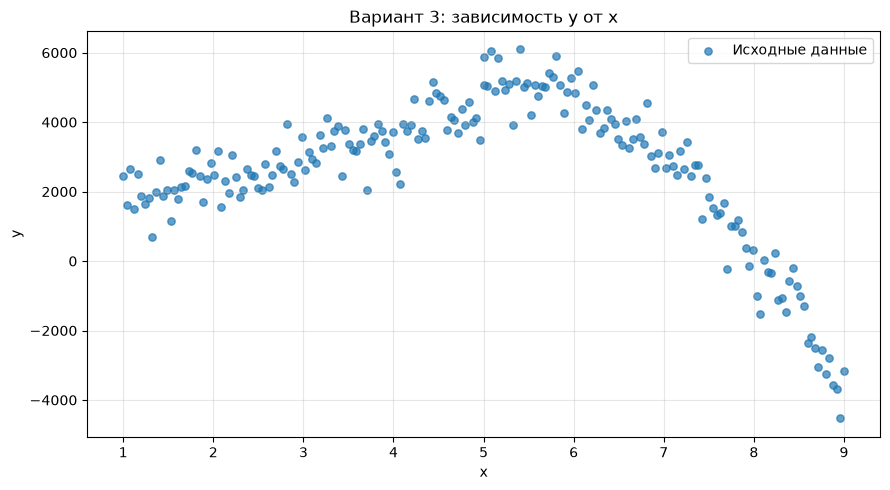

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(data["x"], data["y"], s=28, alpha=0.7, label="Исходные данные")
ax.set_title("Вариант 3: зависимость y от x")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Разделение на обучающую и тестовую выборки

Случайным образом выделим 80% точек (160) для обучения и 20% (40) для итоговой проверки.

`random_state=42` фиксирует случайное разбиение: при повторном запуске получим те же группы. Число 42 не имеет специального математического смысла.

In [4]:
from sklearn.model_selection import train_test_split

X = data[["x"]]
y = data["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Обучающих точек: {len(X_train)}")
print(f"Тестовых точек: {len(X_test)}")

Обучающих точек: 160
Тестовых точек: 40


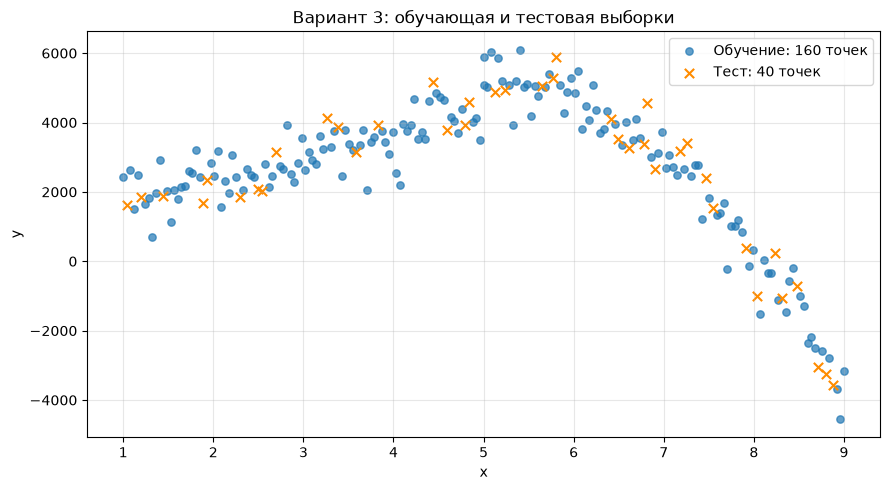

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_train["x"], y_train, s=28, alpha=0.7, label="Обучение: 160 точек")
ax.scatter(X_test["x"], y_test, s=45, marker="x", color="darkorange",
           label="Тест: 40 точек")
ax.set_title("Вариант 3: обучающая и тестовая выборки")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Обучение простой линейной регрессии

Начнём с модели прямой: **ŷ = a · x + b**

Вызов `fit(X_train, y_train)` подбирает a и b, минимизируя сумму квадратов отклонений предсказаний от настоящих ответов на 160 обучающих точках. Тестовые точки в этот вызов не передаются.

Мы уже видим изгиб исходной зависимости, поэтому прямая служит простой отправной моделью. Пока только обучаем её и записываем формулу. Качество оценим на следующем шаге.

In [6]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

a = linear_model.coef_[0]
b = linear_model.intercept_

print(f"Коэффициент a (наклон): {a:.6f}")
print(f"Коэффициент b (свободный член): {b:.6f}")
print(f"Полученная формула: ŷ = {a:.6f} · x {b:+.6f}")

Коэффициент a (наклон): -326.110028
Коэффициент b (свободный член): 4287.438954
Полученная формула: ŷ = -326.110028 · x +4287.438954


Коэффициенты найдены только по обучающей выборке. Отрицательный наклон означает, что эта прямая предсказывает уменьшение y при увеличении x. Она описывает общую линейную тенденцию, но не может воспроизвести сначала рост, а затем спад.

Сам факт успешного обучения не означает, что модель точна. На следующем шаге получим предсказания для отложенных x и сравним их с настоящими y, вычислив ошибки.

## 5. Проверка качества линейной модели

In [7]:
y_pred_test = linear_model.predict(X_test)

comparison = pd.DataFrame({
    "x": X_test["x"],
    "Настоящий y": y_test,
    "Предсказанный y": y_pred_test,
})
comparison["Ошибка"] = comparison["Настоящий y"] - comparison["Предсказанный y"]
comparison["Абсолютная ошибка"] = comparison["Ошибка"].abs()

# Первые 10 тестовых примеров, упорядоченных по x для удобства чтения.
comparison.sort_values("x").head(10).round(2)

,x,Настоящий y,Предсказанный y,Ошибка,Абсолютная ошибка
65,1.04,1613.48,3948.15,-2334.67,2334.67
69,1.20,1859.16,3895.45,-2036.29,2036.29
95,1.44,1881.82,3816.39,-1934.57,1934.57
18,1.89,1688.57,3671.45,-1982.88,1982.88
177,1.93,2354.57,3658.28,-1303.70,1303.70
104,2.29,1839.40,3539.69,-1700.29,1700.29
75,2.49,2094.48,3473.81,-1379.34,1379.34
174,2.54,2032.17,3460.63,-1428.47,1428.47
45,2.70,3162.31,3407.93,-245.62,245.62
152,3.26,4127.87,3223.46,904.41,904.41


### Средние ошибки

- **MAE** — среднее абсолютное отклонение. Измеряется в тех же единицах, что и y.
- **MSE** — средний квадрат отклонения. Измеряется в квадрате единиц y и сильнее реагирует на большие промахи.

Для обеих метрик меньше — лучше при сравнении на одной выборке. MAE и MSE между собой по величине не сравниваем: у них разные единицы.

Посчитаем ошибки и на обучении, и на тесте. Обучающая ошибка показывает, насколько хорошо прямая описывает знакомые точки; тестовая — насколько хорошо она предсказывает отложенные. Все 40 тестовых точек участвуют в расчёте, даже если выше показаны только 10.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred_train = linear_model.predict(X_train)

linear_metrics = pd.DataFrame({
    "Выборка": ["Обучающая (160 точек)", "Тестовая (40 точек)"],
    "MAE": [
        mean_absolute_error(y_train, y_pred_train),
        mean_absolute_error(y_test, y_pred_test),
    ],
    "MSE": [
        mean_squared_error(y_train, y_pred_train),
        mean_squared_error(y_test, y_pred_test),
    ],
}).set_index("Выборка")
linear_metrics.round(2)

,MAE,MSE
Выборка,,
Обучающая (160 точек),1566.3,3604067.24
Тестовая (40 точек),1841.2,4651677.88


### Прямая модели и отклонения тестовых точек

Красная линия — предсказания уже обученной модели. Серые вертикальные отрезки соединяют настоящие тестовые точки с предсказаниями при тех же x. Длина каждого отрезка равна абсолютной ошибке.


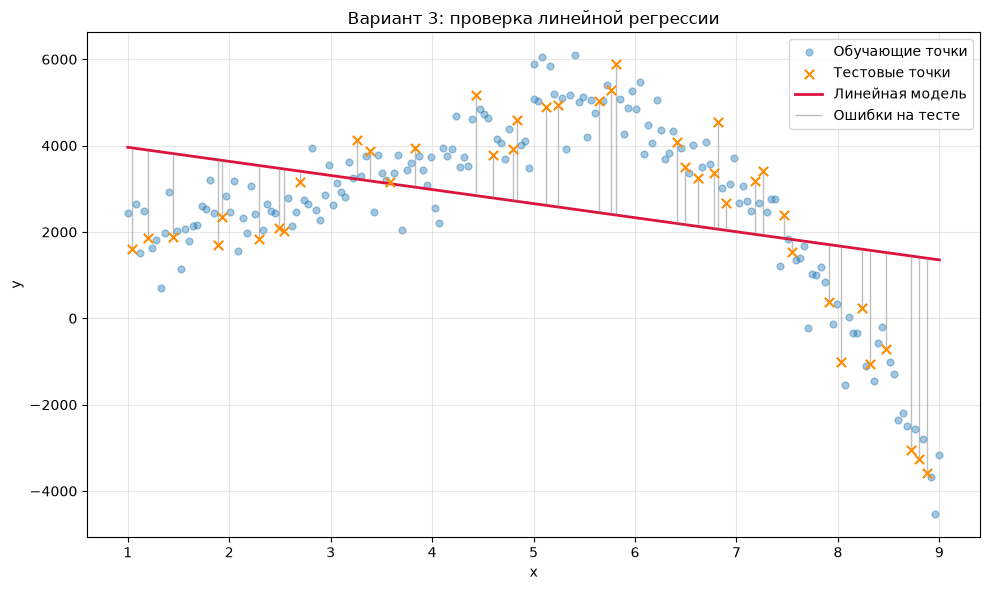

In [9]:
X_line = X.sort_values("x")
y_line = linear_model.predict(X_line)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train["x"], y_train, s=24, alpha=0.4, label="Обучающие точки")
ax.scatter(X_test["x"], y_test, s=45, marker="x", color="darkorange",
           label="Тестовые точки", zorder=3)
ax.plot(X_line["x"], y_line, color="crimson", linewidth=2,
        label="Линейная модель")
ax.vlines(X_test["x"], y_pred_test, y_test, color="gray", alpha=0.5,
          linewidth=1, label="Ошибки на тесте")
ax.set_title("Вариант 3: проверка линейной регрессии")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Полиномиальная регрессия: пробуем кривую

По графику можно предложить перевёрнутую параболу: ŷ = b + a₁x + a₂x². Но парабола симметрична, а рост и спад наших данных выглядят неодинаково. Поэтому сравним полиномы степеней от 1 до 6, включая уже знакомую прямую.

Степень задаёт форму модели, а обучение находит коэффициенты. `PolynomialFeatures` создаёт столбцы x, x² и так далее. Затем `LinearRegression` подбирает их коэффициенты методом наименьших квадратов. Это по-прежнему линейная регрессия по коэффициентам, хотя график может быть кривым.

Более высокая степень обычно позволяет уменьшить ошибку обучения, но не гарантирует точности на новых точках. Поэтому выбираем степень по кросс-валидации, а не по ошибке обучения или теста.

### Выбор степени на обучающих данных

Разделим только 160 обучающих точек на 5 частей. Для каждой степени пять раз обучим модель на 128 точках и проверим на оставшихся 32, каждый раз меняя проверочную часть. Усредним MSE пяти проверок.

Все степени сравниваем на одинаковых разбиениях. Заранее задаём правило: выбираем наименьшую среднюю MSE, при точном равенстве — меньшую степень. Это лучший результат среди рассмотренных вариантов при данном разбиении, а не доказательство оптимальности среди всех возможных функций.

In [10]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)
polynomial_results = []

for degree in range(1, 7):
    candidate = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler()),
        ("regression", LinearRegression()),
    ])
    scores = cross_validate(
        candidate, X_train, y_train, cv=cv,
        scoring="neg_mean_squared_error", return_train_score=True,
    )
    # sklearn возвращает отрицательную MSE: меняем знак для обычной ошибки.
    fold_mse = -scores["test_score"]
    polynomial_results.append({
        "Степень": degree,
        "MSE обучения (средняя)": -scores["train_score"].mean(),
        "MSE проверки CV (средняя)": fold_mse.mean(),
        "MSE проверки CV (стд.)": fold_mse.std(),
    })

cv_results = pd.DataFrame(polynomial_results).set_index("Степень")
best_degree = int(cv_results["MSE проверки CV (средняя)"].idxmin())
print(f"Выбранная степень: {best_degree}")
cv_results.round(2)

Выбранная степень: 5


,MSE обучения (средняя),MSE проверки CV (средняя),MSE проверки CV (стд.)
Степень,,,
1,3584736.40,3777223.29,515076.46
2,825513.76,867559.23,151524.27
3,351781.68,366530.81,87936.04
4,337114.59,358053.81,79934.88
5,309999.50,342464.19,53190.63
6,306818.51,343998.81,51195.69


В таблице «проверка CV» означает проверку внутри обучающих 160 точек, а не на окончательном тесте. Стандартное отклонение показывает разброс MSE между пятью проверками; это не доверительный интервал.

После выбора степени обучим выбранную модель заново на всех 160 обучающих точках. Выведем её формулу. Для предсказаний используем полные коэффициенты модели, а не округлённые числа из текста.

In [11]:
polynomial_model = Pipeline([
    ("poly", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("scale", StandardScaler()),
        ("regression", LinearRegression()),
])
polynomial_model.fit(X_train, y_train)

regression = polynomial_model.named_steps["regression"]
scaler = polynomial_model.named_steps["scale"]
coefficients = regression.coef_ / scaler.scale_
intercept = regression.intercept_ - coefficients @ scaler.mean_
formula = f"ŷ = {intercept:.6f}"
for power, coefficient in enumerate(coefficients, start=1):
    formula += f" {coefficient:+.6f} · x^{power}"
print(formula)

ŷ = -141.142225 +3812.354768 · x^1 -2427.817048 · x^2 +743.712104 · x^3 -94.562501 · x^4 +4.018458 · x^5


### Проверка выбранной модели на отложенных точках

Теперь степень и коэффициенты зафиксированы. Получим предсказания на тесте и сравним с простой прямой. По результатам этой таблицы степень повторно не выбираем.

In [12]:
poly_pred_train = polynomial_model.predict(X_train)
poly_pred_test = polynomial_model.predict(X_test)

model_comparison = pd.DataFrame([
    {"Модель": name,
     "MAE обучения": mean_absolute_error(y_train, train_pred),
     "MAE теста": mean_absolute_error(y_test, test_pred),
     "MSE обучения": mean_squared_error(y_train, train_pred),
     "MSE теста": mean_squared_error(y_test, test_pred)}
    for name, train_pred, test_pred in [
        ("Прямая", y_pred_train, y_pred_test),
        (f"Полином степени {best_degree}", poly_pred_train, poly_pred_test),
    ]
]).set_index("Модель")
model_comparison.round(2)

,MAE обучения,MAE теста,MSE обучения,MSE теста
Модель,,,,
Прямая,1566.30,1841.20,3604067.24,4651677.88
Полином степени 5,426.43,504.73,313143.80,353399.91


### Сравнение формы кривых

Покажем прямую, параболу и выбранный полином. Параболу обучаем только на обучающих данных, чтобы увидеть, насколько удачной была первоначальная гипотеза. Если выбрана степень 2, она и является итоговой кривой.

Для гладких линий создаём плотную сетку x внутри исходного диапазона. Это точки для рисования предсказаний, а не новые измерения.

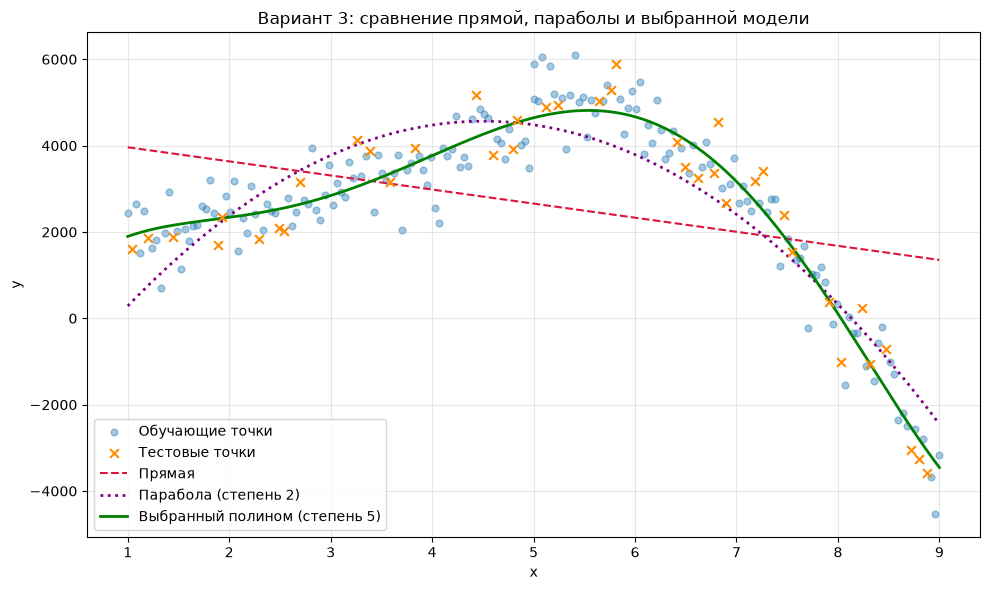

In [13]:
quadratic_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
        ("regression", LinearRegression()),
])
quadratic_model.fit(X_train, y_train)

X_grid = pd.DataFrame({"x": np.linspace(X["x"].min(), X["x"].max(), 400)})
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train["x"], y_train, s=24, alpha=0.4, label="Обучающие точки")
ax.scatter(X_test["x"], y_test, s=40, marker="x", color="darkorange",
           label="Тестовые точки", zorder=3)
ax.plot(X_grid["x"], linear_model.predict(X_grid), "--", color="crimson",
        label="Прямая")
if best_degree != 2:
    ax.plot(X_grid["x"], quadratic_model.predict(X_grid), ":", color="purple",
            linewidth=2, label="Парабола (степень 2)")
ax.plot(X_grid["x"], polynomial_model.predict(X_grid), color="green",
        linewidth=2, label=f"Выбранный полином (степень {best_degree})")
ax.set_title("Вариант 3: сравнение прямой, параболы и выбранной модели")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Вывод по полиномиальной модели

Парабола оказалась полезной гипотезой: средняя MSE кросс-валидации снизилась примерно с 3 777 223 для прямой до 867 559. Среди степеней 1–6 минимальную среднюю MSE показала степень 5 (342 464), поэтому по заранее выбранному правилу используем её.

У степени 6 ошибка обучения меньше, но средняя ошибка проверки немного больше (343 999). Это пример того, что усложнение и лучшая подгонка обучающих точек не гарантируют улучшения предсказаний. Разница между степенями 5 и 6 мала относительно разброса между разбиениями: нельзя утверждать, что степень 5 всегда лучше.

На отложенных 40 точках MAE уменьшилась с 1841,20 до 504,73, а MSE — с 4 651 677,88 до 353 399,91. Выбранная кривая лучше воспроизводит плавный рост и более резкий спад данных, не проходя через каждую точку.

Вывод относится к данному набору и разбиению. Поведение полинома за пределами x от 1 до 9 здесь не проверялось.

## 7. Анализ остатков: что скрывается за средней ошибкой

Остаток — разность **e = y − ŷ**. Положительный остаток означает, что модель занизила ответ, отрицательный — завысила. Абсолютная величина остатка показывает размер промаха.

Исследуем 40 тестовых точек уже выбранного полинома. Модель не переобучаем и её параметры по этим результатам не меняем. MAE — средний промах, а не максимальная ошибка и не гарантия точности каждого предсказания.

In [14]:
residual_table = pd.DataFrame({
    "x": X_test["x"],
    "Настоящий y": y_test,
    "Предсказанный y": poly_pred_test,
})
residual_table["Остаток"] = residual_table["Настоящий y"] - residual_table["Предсказанный y"]
residual_table["Абсолютная ошибка"] = residual_table["Остаток"].abs()
residual_table.index.name = "Индекс строки данных (с 0)"

residuals = residual_table["Остаток"]
absolute_errors = residual_table["Абсолютная ошибка"]

# Берём 36-ю по величине ошибку из 40: минимум 90% наблюдений не выше неё.
coverage_rank = int(np.ceil(0.9 * len(absolute_errors)))
error_limit_90 = absolute_errors.sort_values().iloc[coverage_rank - 1]
covered_count = int((absolute_errors <= error_limit_90).sum())

residual_summary = pd.Series({
    "Средний остаток (со знаком)": residuals.mean(),
    "MAE — средняя абсолютная ошибка": absolute_errors.mean(),
    "Медианная абсолютная ошибка": absolute_errors.median(),
    "Предел для минимум 90% тестовых ошибок": error_limit_90,
    "Максимальная абсолютная ошибка": absolute_errors.max(),
}, name="Значение")
print(f"В предел 90% укладываются {covered_count} из {len(absolute_errors)} тестовых точек.")
residual_summary.round(2).to_frame()

В предел 90% укладываются 36 из 40 тестовых точек.


,Значение
Средний остаток (со знаком),30.01
MAE — средняя абсолютная ошибка,504.73
Медианная абсолютная ошибка,510.03
Предел для минимум 90% тестовых ошибок,974.71
Максимальная абсолютная ошибка,1131.61


Медиана характеризует середину распределения ошибок. Предел 90% здесь вычислен как 36-я ошибка в отсортированном списке из 40. Это описание имеющейся тестовой выборки, а не обещание, что 90% будущих ошибок обязательно будут такими же.

Средний остаток учитывает знак: положительные и отрицательные ошибки могут компенсироваться. Поэтому даже близкий к нулю средний остаток не означает маленьких промахов.

Посмотрим на пять самых больших ошибок. Большой остаток сам по себе не доказывает, что строка ошибочна или её надо удалить.

In [15]:
worst_predictions = residual_table.nlargest(5, "Абсолютная ошибка")
worst_predictions.round(2)

,x,Настоящий y,Предсказанный y,Остаток,Абсолютная ошибка
Индекс строки данных (с 0),,,,,
132,5.81,5898.38,4766.77,1131.61,1131.61
152,3.26,4127.87,3053.32,1074.55,1074.55
76,8.03,-1010.10,-2.72,-1007.38,1007.38
56,6.82,4549.93,3568.70,981.23,981.23
82,8.23,230.55,-744.16,974.71,974.71


### Графики ошибок

Слева показаны остатки в зависимости от x. Горизонтальная линия 0 означает точное предсказание. Дуга, наклон или длинные последовательности остатков одного знака могут указывать на пропущенную закономерность. Расширение разброса вправо может указывать на зависимость величины ошибки от x.

Справа — отсортированные абсолютные ошибки. Горизонтальные линии показывают средний промах и предел 90%, чтобы было видно, насколько отдельные ошибки превышают среднее. Номера по горизонтали — места после сортировки, а не исходные строки.

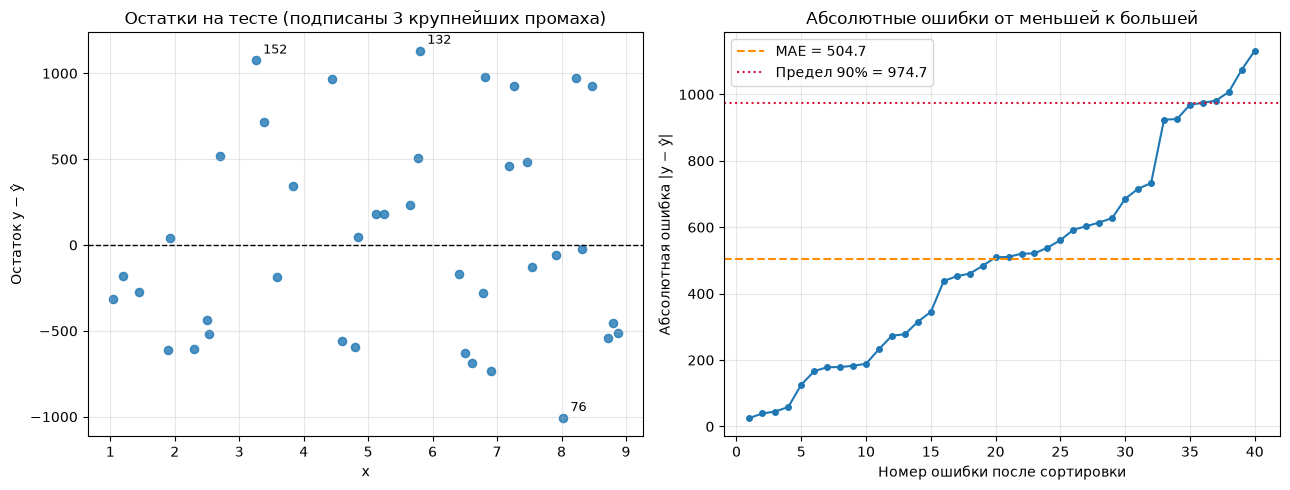

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(residual_table["x"], residuals, s=35, alpha=0.8)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
for row_index, row in worst_predictions.head(3).iterrows():
    axes[0].annotate(str(row_index), (row["x"], row["Остаток"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=9)
axes[0].set_title("Остатки на тесте (подписаны 3 крупнейших промаха)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Остаток y − ŷ")

sorted_errors = absolute_errors.sort_values().to_numpy()
axes[1].plot(np.arange(1, len(sorted_errors) + 1), sorted_errors, "o-", markersize=4)
axes[1].axhline(absolute_errors.mean(), color="darkorange", linestyle="--",
               label=f"MAE = {absolute_errors.mean():.1f}")
axes[1].axhline(error_limit_90, color="crimson", linestyle=":",
               label=f"Предел 90% = {error_limit_90:.1f}")
axes[1].set_title("Абсолютные ошибки от меньшей к большей")
axes[1].set_xlabel("Номер ошибки после сортировки")
axes[1].set_ylabel("Абсолютная ошибка |y − ŷ|")
axes[1].legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по остаткам

На 40 тестовых точках MAE равна 504,73, медианная абсолютная ошибка — 510,03. Близость этих чисел показывает, что среднее не объясняется лишь одним огромным промахом: ошибки порядка 500 характерны для середины этой выборки.

36 из 40 ошибок не превышают 974,71. Максимальный промах — 1131,61: при x ≈ 5,81 модель предсказала 4766,77 вместо 5898,38. Это наблюдаемые значения на текущем тесте, а не гарантированные границы будущих ошибок.

Средний остаток составляет +30,01: в среднем по этой выборке предсказания немного занижены. Малый средний остаток не отменяет MAE около 505, поскольку ошибки разных знаков компенсируются.

На графике остатки встречаются по обе стороны нуля, без столь выраженной общей дуги, как у прямой. При этом в левом краю и около правого края заметны группы отрицательных остатков; на 40 точках нельзя уверенно объявить ошибки полностью случайными или модель исчерпывающей. Анализ не доказывает нормальность ошибок, постоянство их разброса или достижение уровня шума.

Модель существенно лучше прямой, но практическую допустимость ошибок определить нельзя: в задании не указаны смысл y и требуемая точность. По тестовым остаткам модель дополнительно не настраиваем.

## 8. Итоговый вывод

В работе исследован набор данных варианта 3: 200 пар (x, y) без пропусков. Построена диаграмма рассеяния, данные разделены на 160 обучающих и 40 тестовых наблюдений с фиксированным random_state=42.

С помощью scikit-learn обучена линейная регрессия и рассмотрены полиномы степеней 1–6. Степень выбрана по минимальной средней MSE пятикратной кросс-валидации только на обучающих данных. Среди проверенных вариантов выбран полином степени 5. Признаки нормализованы внутри Pipeline; коэффициенты ниже приведены для исходного x.

Получена эмпирическая формула (коэффициенты округлены):

ŷ = −141,142225 + 3812,354768·x − 2427,817048·x² + 743,712104·x³ − 94,562501·x⁴ + 4,018458·x⁵.

На тестовой выборке MAE снизилась с 1841,20 у прямой до 504,73 у полинома, а MSE — с 4 651 677,88 до 353 399,91. Полином лучше описывает плавный рост и последующий более резкий спад зависимости. Анализ остатков показал, что 36 из 40 тестовых ошибок не превышают 974,71, максимальная ошибка равна 1131,61.

Результаты подтверждают улучшение относительно простой линейной модели на данном разбиении. Они не доказывают оптимальность выбранной функции среди всех возможных моделей. Порог допустимой ошибки и физический смысл y в задании не указаны, поэтому практическую достаточность точности оценить нельзя. За пределами диапазона x от 1 до 9 модель не проверялась.

Цель работы достигнута: получена эмпирическая формула, её качество оценено на отложенных данных, результаты визуализированы.